# 02 · Training EfficientNet-B0 (leakage-aware and naive splits)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Rishabh-bgp/brain-tumor-mri-classification/blob/main/notebooks/02_training_efficientnet_b0.ipynb)

Fine-tunes an ImageNet-pretrained EfficientNet-B0 (timm) on 224×224 greyscale slices. The *leakage-aware* run uses the group-based split from notebook 01; the *naive* run uses the original Training folder with a random image-level validation split, for comparison. Set `FORCE_TRAIN = True` to retrain (about 30 min per run on an 8-core CPU, a few minutes on a Colab GPU). When checkpoints already exist the notebook shows the logged history of the run that produced the committed results.

*Rishabh Aryan · M.Tech (AI & Data Science), IIIT Bhagalpur. Research and education code, not a medical device.*

In [1]:
# --- Setup: works locally (repo checkout) and on Google Colab ---
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("brain-tumor-mri-classification"):
        subprocess.run(["git", "clone", "-q", "https://github.com/Rishabh-bgp/brain-tumor-mri-classification.git"], check=True)
    os.chdir("brain-tumor-mri-classification")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "kagglehub", "imagehash", "captum",
                    "onnx", "onnxruntime", "scikit-image"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
print("working directory:", os.getcwd())

working directory: /workspace/brain-tumor-mri/repo


In [2]:
import torch
print("PyTorch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU (Colab: Runtime > Change runtime type > GPU for faster training)")

PyTorch 2.15.0+cpu | CUDA available: False
Running on CPU (Colab: Runtime > Change runtime type > GPU for faster training)


In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Path to dataset files:", path)

Path to dataset files: /home/box/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2


In [4]:
FORCE_TRAIN = False
from pathlib import Path
for run in ("clean", "naive"):
    ckpt = Path(f"results/runs/{run}/best.pt")
    if FORCE_TRAIN or not ckpt.exists():
        subprocess.run([sys.executable, "-m", "btmri.train", "--run", run, "--epochs", "12"], cwd="src", check=True)
    else:
        print(f"[{run}] using existing checkpoint {ckpt} (set FORCE_TRAIN = True to retrain)")

[clean] using existing checkpoint results/runs/clean/best.pt (set FORCE_TRAIN = True to retrain)
[naive] using existing checkpoint results/runs/naive/best.pt (set FORCE_TRAIN = True to retrain)


In [5]:
import pandas as pd
for run in ("clean", "naive"):
    h = pd.read_csv(f"results/runs/{run}/history.csv")
    print(f"=== {run} run: best epoch by validation macro-F1 = {int(h.loc[h.val_macro_f1.idxmax(), 'epoch'])}")
    display(h.round(4))

=== clean run: best epoch by validation macro-F1 = 11


,epoch,train_loss,val_loss,val_acc,val_macro_f1,lr,seconds
0,1,1.2567,0.7693,0.7949,0.7830,0.0005,129.8253
1,2,0.3004,0.2527,0.9431,0.9458,0.0005,127.4524
2,3,0.1421,0.5532,0.9072,0.9152,0.0005,106.0436
3,4,0.1023,0.1000,0.9701,0.9711,0.0004,113.0313
4,5,0.0960,0.0832,0.9716,0.9734,0.0004,697.2702
5,6,0.0540,0.0989,0.9805,0.9818,0.0003,115.5801
6,7,0.0192,0.0788,0.9760,0.9764,0.0002,106.5253
7,8,0.0186,0.0826,0.9790,0.9797,0.0002,527.9103
8,9,0.0168,0.0719,0.9835,0.9842,0.0001,111.5602
9,10,0.0117,0.0734,0.9850,0.9856,0.0000,111.2585


=== naive run: best epoch by validation macro-F1 = 8


,epoch,train_loss,val_loss,val_acc,val_macro_f1,lr,seconds
0,1,1.2002,0.3004,0.9095,0.9089,0.0005,143.9760
1,2,0.2516,0.2606,0.9321,0.9312,0.0005,1982.4785
2,3,0.1495,0.1059,0.9631,0.9630,0.0005,137.1576
3,4,0.0770,0.1188,0.9667,0.9666,0.0004,126.7644
4,5,0.0450,0.0684,0.9821,0.9822,0.0004,132.1505
5,6,0.0439,0.0608,0.9821,0.9821,0.0003,130.0025
6,7,0.0359,0.0466,0.9869,0.9869,0.0002,365.7047
7,8,0.0176,0.0566,0.9905,0.9905,0.0002,113.3037
8,9,0.0172,0.0693,0.9845,0.9845,0.0001,120.5007
9,10,0.0089,0.0687,0.9845,0.9845,0.0000,134.0778


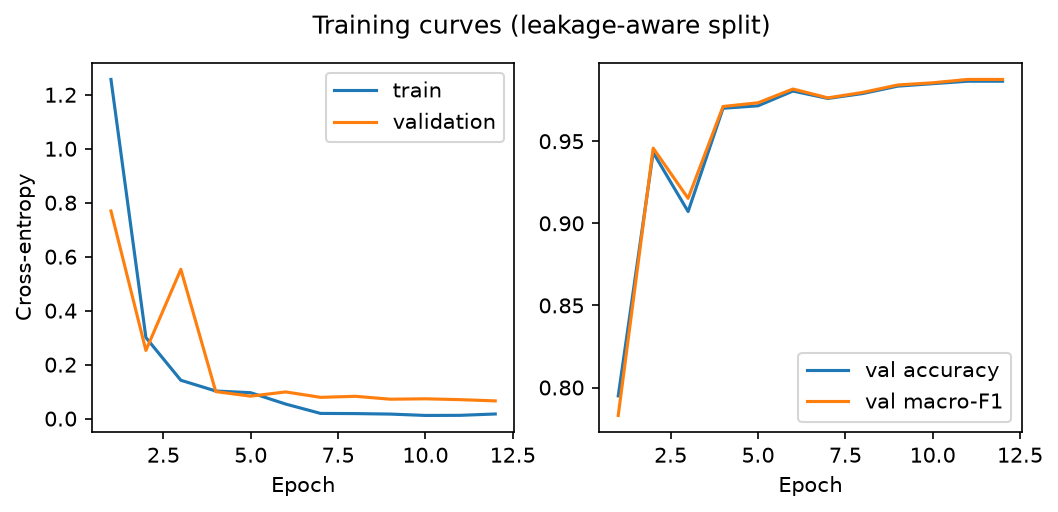

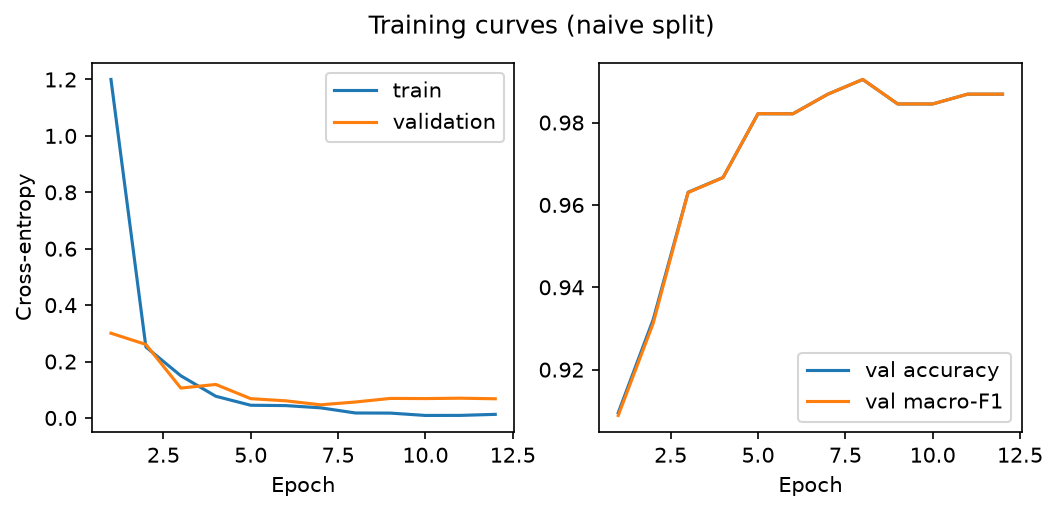

In [6]:
from IPython.display import Image, display
for run in ("clean", "naive"):
    display(Image(f"results/figures/training_curves_{run}.png", width=760))

**Training recipe** (see `src/btmri/train.py`): AdamW (lr 5e-4, weight decay 1e-4), one-cycle schedule, batch 32, 12 epochs, inverse-frequency class weights, augmentation = random resized crop (scale 0.8–1), horizontal flip, ±10° rotation / 5% translation, brightness/contrast jitter 0.2; seed 42; the checkpoint with the best validation macro-F1 is kept.